# Análise de desempenho — Etapa 2 (MPI)

Este caderno consolida os benchmarks MPI do Conjunto de Mandelbrot. Ele compara a decomposição por **faixas contíguas** (`block`) com a distribuição **cíclica por linhas** (`cyclic`), mede o custo de coleta e contrasta os resultados com OpenMP.

As métricas seguem a Aula 03: $S(n,p)=T(n)/T(n,p)$, $E(n,p)=S(n,p)/p$ e $FLB=(T_{max}-T_{min})/T_{max}$. Portanto, para o FLB, **0% é o balanceamento ideal**.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
RESULTS = ROOT / 'results'
PLOTS = RESULTS / 'graficos'
TABLES = RESULTS / 'tabelas'
PLOTS.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13})
CORES = {'block': '#c44e52', 'cyclic': '#1f77b4', 'openmp': '#2ca02c'}
print(f'Diretório de resultados: {RESULTS.resolve()}')

Diretório de resultados: /home/enzosarmento/Documents/2026.2/processamento-paralelo/conjunto-de-mandelbrot/results


## Ambiente e método experimental

Os ensaios usam cinco repetições para cada $P\in[1,12]$, nos modos padrão (4096×4096, `MAX_ITER=1000`) e Seahorse (4096×4096, `MAX_ITER=5000`). O processador possui 6 núcleos físicos e 12 contextos lógicos por SMT. Logo, $P\leq12$ não caracteriza *oversubscription*; os pontos acima de 6 avaliam a contribuição dos contextos lógicos adicionais.

O tempo $T_p$ exclui a E/S dos arquivos. A implementação MPI sincroniza antes e depois da região medida, de modo que a janela termina quando o último processo conclui cálculo, coleta e eventual rearranjo.

In [2]:
ambiente = pd.DataFrame([
    ('CPU', 'AMD Ryzen 5 5600H with Radeon Graphics'),
    ('Núcleos físicos / contextos lógicos', '6 / 12 (SMT)'),
    ('Topologia', '1 nó NUMA; L3 de 16 MiB'),
    ('Compilador MPI', 'GCC/MPICH 13.3.0, -O3 -march=native -ffast-math'),
    ('Estratégias', 'block (faixas contíguas) e cyclic (round-robin por linhas)'),
    ('Repetições', '5 por configuração')
], columns=['Parâmetro', 'Configuração'])
display(ambiente)
ambiente.to_markdown(TABLES / 'tabela_mpi_ambiente.md', index=False)

,Parâmetro,Configuração
0,CPU,AMD Ryzen 5 5600H with Radeon Graphics
1,Núcleos físicos / contextos lógicos,6 / 12 (SMT)
2,Topologia,1 nó NUMA; L3 de 16 MiB
3,Compilador MPI,"GCC/MPICH 13.3.0, -O3 -march=native -ffast-math"
4,Estratégias,block (faixas contíguas) e cyclic (round-robin...
5,Repetições,5 por configuração


## Carregamento e normalização das métricas

Os CSVs guardam os tempos brutos por execução. O FLB é sempre recalculado abaixo usando $T_{max}$ e $T_{min}$, inclusive ao abrir CSVs antigos que tenham sido gerados antes da correção da fórmula.

In [3]:
def carregar_mpi(nome):
    df = pd.read_csv(RESULTS / nome)
    obrigatorias = {'processos', 'estrategia', 't1_s', 'tp_s', 't_max_s', 't_min_s', 't_comm_s'}
    faltantes = obrigatorias.difference(df.columns)
    if faltantes:
        raise ValueError(f'{nome}: colunas ausentes: {sorted(faltantes)}')
    df['fator_balanceamento'] = np.where(
        df['t_max_s'] > 0, (df['t_max_s'] - df['t_min_s']) / df['t_max_s'], 0.0)
    # Recalcular também as métricas derivadas evita inconsistência após nova coleta.
    df['speedup'] = df['t1_s'] / df['tp_s']
    df['eficiencia'] = df['speedup'] / df['processos']
    return df

df_padrao = carregar_mpi('benchmark_mpi_padrao.csv')
df_seahorse = carregar_mpi('benchmark_mpi_seahorse.csv')
print(f'Padrão: {len(df_padrao)} medições; Seahorse: {len(df_seahorse)} medições')
display(df_padrao.head())

Padrão: 120 medições; Seahorse: 120 medições


,modo,repeticao,processos,estrategia,t1_s,tp_s,t_max_s,t_min_s,t_avg_s,t_gather_s,t_reorder_s,t_comm_s,speedup,eficiencia,fator_balanceamento
0,padrao,1,1,block,0.829644,0.837442,0.801893,0.801893,0.801893,0.035548,0.000000,0.035548,0.990688,0.990688,0.000000
1,padrao,1,1,cyclic,0.829644,0.873793,0.797654,0.797654,0.797654,0.036382,0.039755,0.076137,0.949474,0.949474,0.000000
2,padrao,1,2,block,0.829644,0.439617,0.404786,0.403568,0.404177,0.034688,0.000000,0.034688,1.887197,0.943599,0.003009
3,padrao,1,2,cyclic,0.829644,0.477088,0.402210,0.401410,0.401810,0.034911,0.039862,0.074773,1.738975,0.869487,0.001989
4,padrao,1,3,block,0.829644,0.305489,0.270519,0.268711,0.269318,0.034858,0.000000,0.034858,2.715790,0.905263,0.006683


In [4]:
def agregar(df):
    return df.groupby(['estrategia', 'processos'], as_index=False).agg(
        t1_mean=('t1_s', 'mean'),
        tp_mean=('tp_s', 'mean'), tp_std=('tp_s', 'std'),
        speedup_mean=('speedup', 'mean'), speedup_std=('speedup', 'std'),
        eficiencia_mean=('eficiencia', 'mean'),
        flb_mean=('fator_balanceamento', 'mean'),
        tmax_mean=('t_max_s', 'mean'), tmin_mean=('t_min_s', 'mean'),
        gather_mean=('t_gather_s', 'mean'), reorder_mean=('t_reorder_s', 'mean'),
        comm_mean=('t_comm_s', 'mean')
    )

agg_padrao = agregar(df_padrao)
agg_seahorse = agregar(df_seahorse)
display(agg_padrao.head())

,estrategia,processos,t1_mean,tp_mean,tp_std,speedup_mean,speedup_std,eficiencia_mean,flb_mean,tmax_mean,tmin_mean,gather_mean,reorder_mean,comm_mean
0,block,1,0.834888,0.834385,0.005304,1.000623,0.008362,1.000623,0.000000,0.798085,0.798085,0.036300,0.0,0.036300
1,block,2,0.834888,0.439406,0.000926,1.900062,0.017730,0.950031,0.001902,0.404017,0.403249,0.035269,0.0,0.035269
2,block,3,0.834888,0.307617,0.001385,2.714059,0.018186,0.904686,0.006911,0.271183,0.269308,0.036291,0.0,0.036291
3,block,4,0.834888,0.345810,0.001658,2.414305,0.016030,0.603576,0.665590,0.308540,0.103178,0.037097,0.0,0.037097
4,block,5,0.834888,0.340926,0.004718,2.449305,0.042304,0.489861,0.918503,0.303483,0.024743,0.037255,0.0,0.037255


## Caso padrão

A tabela seleciona, para cada número de processos, a estratégia que obteve o menor $T_p$ médio.

In [5]:
def tabela_melhores(agg, nome):
    melhores = agg.loc[agg.groupby('processos')['tp_mean'].idxmin()].sort_values('processos').copy()
    exibir = melhores[['processos', 'estrategia', 'tp_mean', 'tp_std', 'speedup_mean',
                       'eficiencia_mean', 'flb_mean', 'comm_mean']].rename(columns={
        'processos': 'P', 'estrategia': 'Estratégia', 'tp_mean': 'Tp médio (s)',
        'tp_std': 'Desvio (s)', 'speedup_mean': 'Speedup',
        'eficiencia_mean': 'Eficiência', 'flb_mean': 'FLB', 'comm_mean': 'Tcomm (s)'})
    exibir.to_markdown(TABLES / f'tabela_mpi_melhores_{nome}.md', index=False, floatfmt='.6f')
    return exibir

melhores_padrao = tabela_melhores(agg_padrao, 'padrao')
display(melhores_padrao.style.format({'Eficiência': '{:.2%}', 'FLB': '{:.2%}'}))

,P,Estratégia,Tp médio (s),Desvio (s),Speedup,Eficiência,FLB,Tcomm (s)
0,1,block,0.834385,0.005304,1.000623,100.06%,0.00%,0.036300
1,2,block,0.439406,0.000926,1.900062,95.00%,0.19%,0.035269
2,3,block,0.307617,0.001385,2.714059,90.47%,0.69%,0.036291
15,4,cyclic,0.283480,0.002782,2.945274,73.63%,0.48%,0.078443
16,5,cyclic,0.248408,0.003982,3.361606,67.23%,0.84%,0.082437
17,6,cyclic,0.222328,0.002169,3.755504,62.59%,1.67%,0.082257
18,7,cyclic,0.224083,0.011424,3.733564,53.34%,13.35%,0.088200
19,8,cyclic,0.220113,0.013733,3.805125,47.56%,13.42%,0.100667
20,9,cyclic,0.199039,0.012018,4.206173,46.74%,13.47%,0.092594
21,10,cyclic,0.207196,0.013175,4.044242,40.44%,14.29%,0.109611


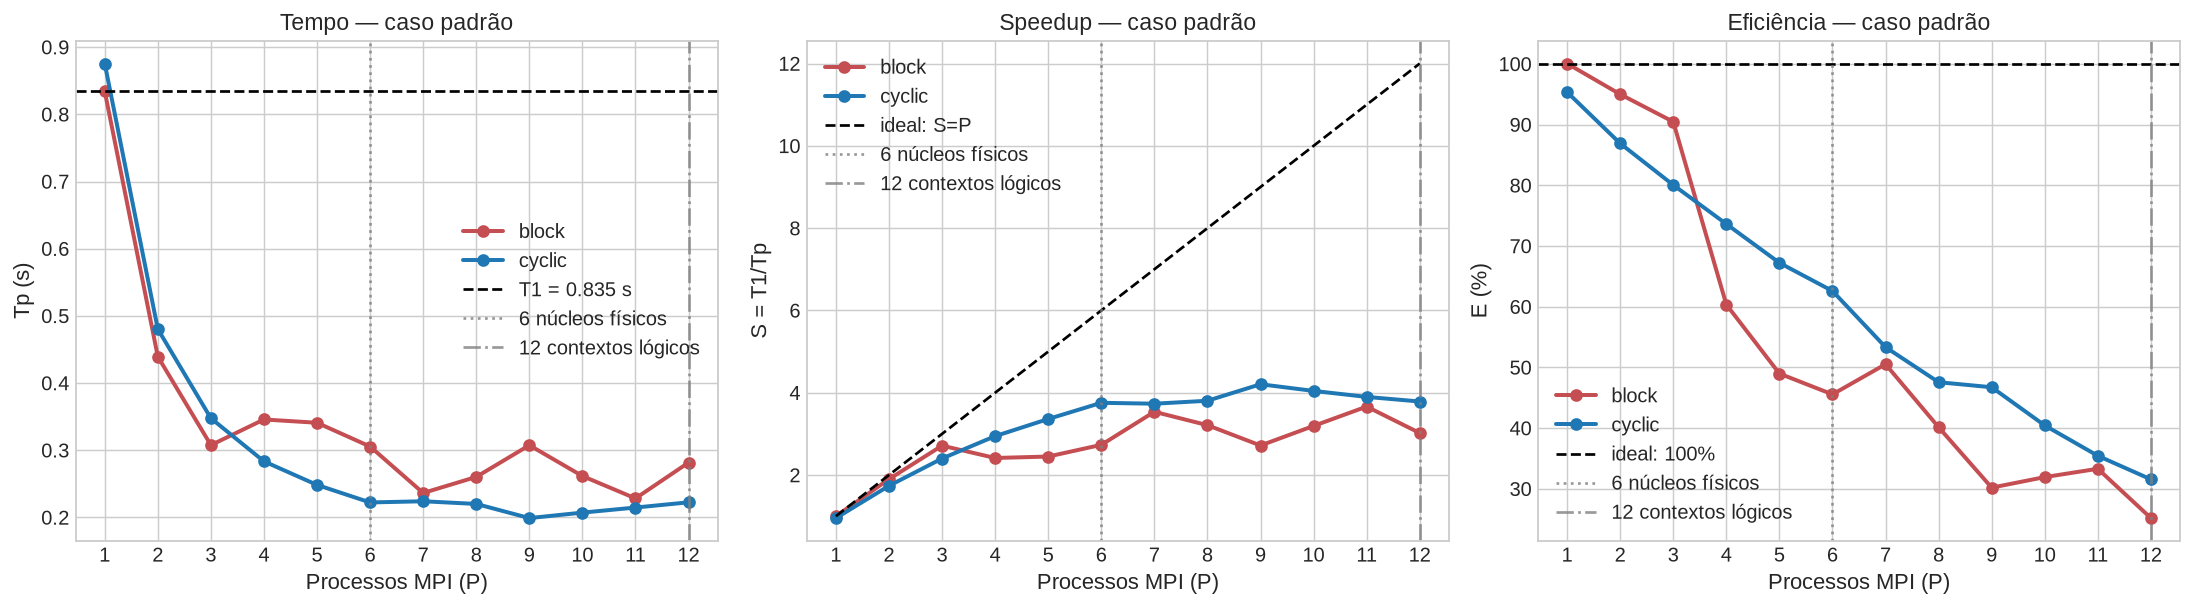

In [6]:
def marcar_hardware(ax):
    ax.axvline(6, color='gray', ls=':', alpha=.8, label='6 núcleos físicos')
    ax.axvline(12, color='gray', ls='-.', alpha=.8, label='12 contextos lógicos')

def curvas_desempenho(agg, titulo, arquivo):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    processos = sorted(agg['processos'].unique())
    t1 = agg['t1_mean'].mean()
    for estrategia, sub in agg.groupby('estrategia'):
        sub = sub.sort_values('processos')
        axes[0].plot(sub['processos'], sub['tp_mean'], marker='o', lw=2.2,
                     color=CORES[estrategia], label=estrategia)
        axes[1].plot(sub['processos'], sub['speedup_mean'], marker='o', lw=2.2,
                     color=CORES[estrategia], label=estrategia)
        axes[2].plot(sub['processos'], sub['eficiencia_mean'] * 100, marker='o', lw=2.2,
                     color=CORES[estrategia], label=estrategia)
    axes[0].axhline(t1, color='black', ls='--', label=f'T1 = {t1:.3f} s')
    axes[1].plot(processos, processos, color='black', ls='--', label='ideal: S=P')
    axes[2].axhline(100, color='black', ls='--', label='ideal: 100%')
    for ax in axes:
        marcar_hardware(ax); ax.set_xticks(processos); ax.legend()
    axes[0].set(title=f'Tempo — {titulo}', xlabel='Processos MPI (P)', ylabel='Tp (s)')
    axes[1].set(title=f'Speedup — {titulo}', xlabel='Processos MPI (P)', ylabel='S = T1/Tp')
    axes[2].set(title=f'Eficiência — {titulo}', xlabel='Processos MPI (P)', ylabel='E (%)')
    fig.tight_layout()
    fig.savefig(PLOTS / arquivo)
    plt.show()

curvas_desempenho(agg_padrao, 'caso padrão', 'fig_mpi_1_desempenho_padrao.png')

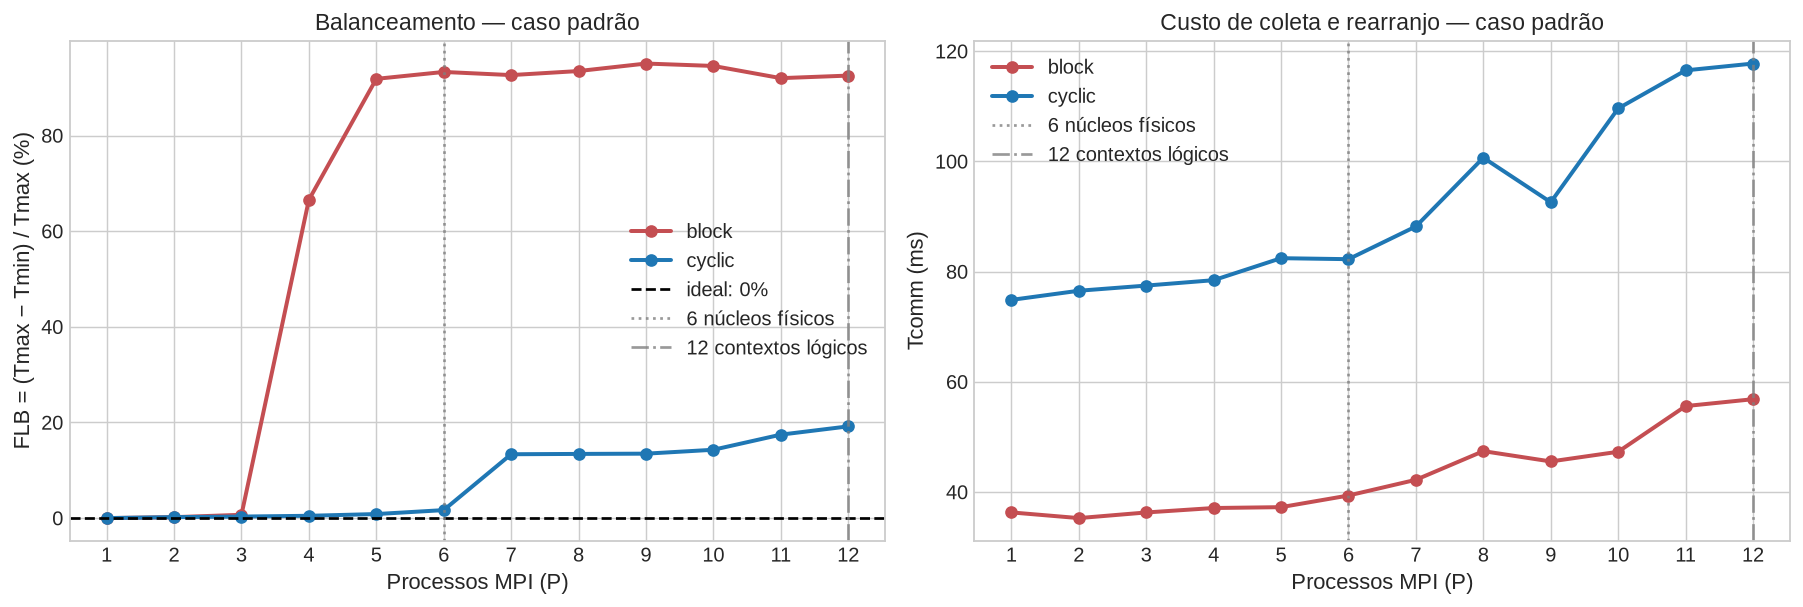

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for estrategia, sub in agg_padrao.groupby('estrategia'):
    sub = sub.sort_values('processos')
    ax1.plot(sub['processos'], sub['flb_mean'] * 100, marker='o', lw=2.2,
             color=CORES[estrategia], label=estrategia)
    ax2.plot(sub['processos'], sub['comm_mean'] * 1000, marker='o', lw=2.2,
             color=CORES[estrategia], label=estrategia)
ax1.axhline(0, color='black', ls='--', label='ideal: 0%')
for ax in (ax1, ax2):
    marcar_hardware(ax); ax.set_xticks(range(1, 13)); ax.legend()
ax1.set(title='Balanceamento — caso padrão', xlabel='Processos MPI (P)',
        ylabel='FLB = (Tmax − Tmin) / Tmax (%)')
ax2.set(title='Custo de coleta e rearranjo — caso padrão', xlabel='Processos MPI (P)',
        ylabel='Tcomm (ms)')
fig.tight_layout()
fig.savefig(PLOTS / 'fig_mpi_2_balanceamento_comunicacao_padrao.png')
plt.show()

## Vale dos Cavalos-Marinhos

O cenário Seahorse torna a heterogeneidade de custo mais visível. A comparação abaixo permite observar se o custo adicional do rearranjo cíclico é compensado pelo menor tempo ocioso.

,P,Estratégia,Tp médio (s),Desvio (s),Speedup,Eficiência,FLB,Tcomm (s)
0,1,block,3.100827,0.025040,1.010875,101.09%,0.00%,0.035646
13,2,cyclic,1.628236,0.029514,1.925181,96.26%,0.15%,0.080965
14,3,cyclic,1.120980,0.009899,2.796237,93.21%,0.39%,0.077987
15,4,cyclic,0.863959,0.013663,3.628474,90.71%,0.50%,0.081656
16,5,cyclic,0.716222,0.014083,4.377310,87.55%,0.95%,0.084010
17,6,cyclic,0.620273,0.025745,5.059591,84.33%,1.08%,0.088029
18,7,cyclic,0.579153,0.018026,5.416051,77.37%,7.78%,0.089514
19,8,cyclic,0.527864,0.022114,5.946081,74.33%,7.96%,0.094650
20,9,cyclic,0.502679,0.022021,6.245465,69.39%,8.63%,0.111681
21,10,cyclic,0.500518,0.079418,6.364602,63.65%,11.77%,0.122302


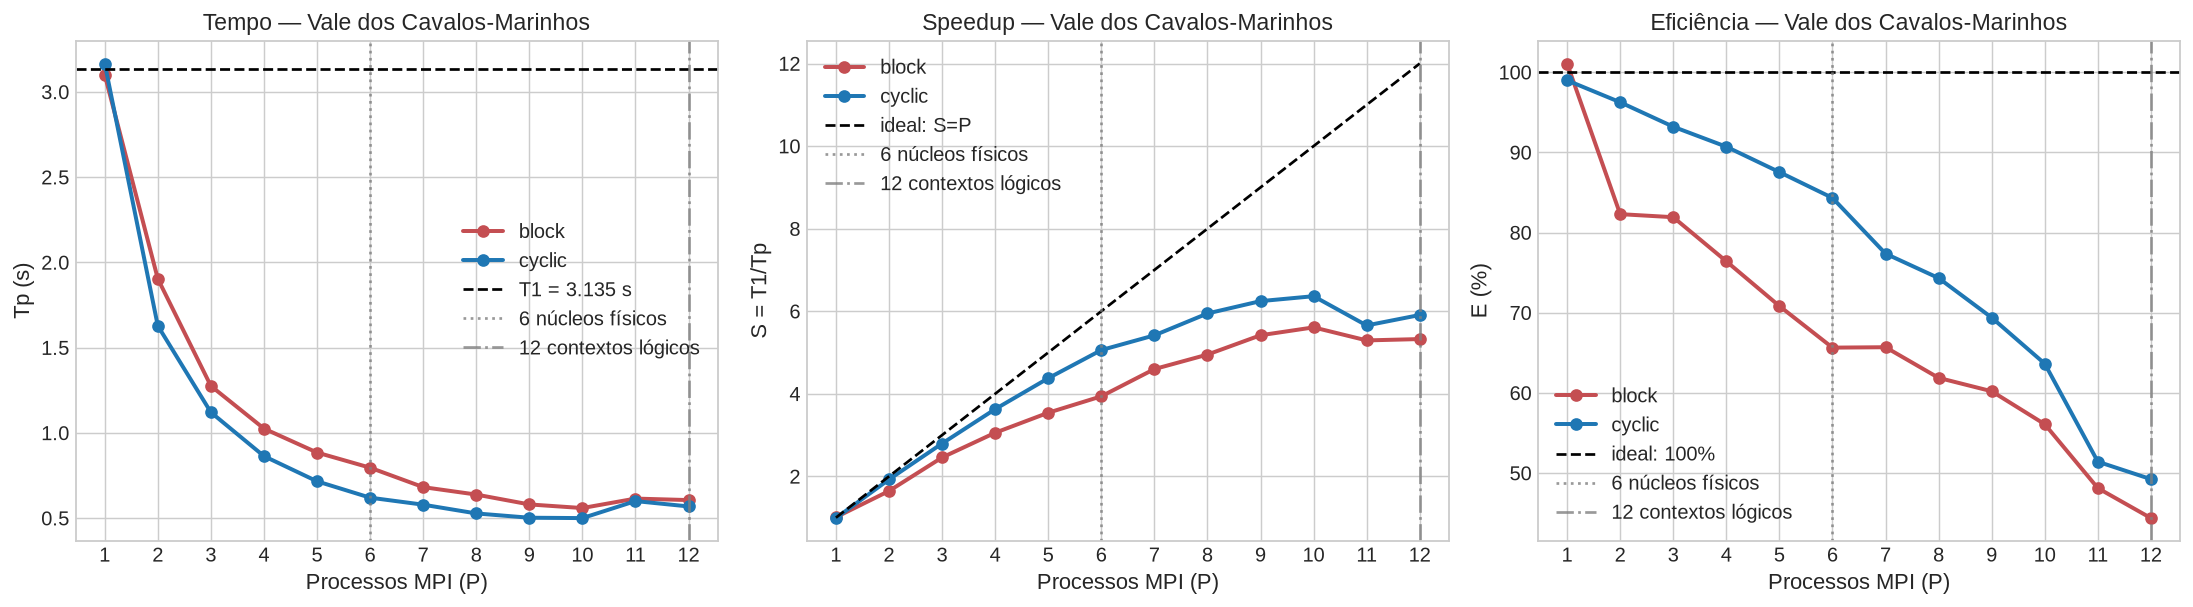

In [8]:
melhores_seahorse = tabela_melhores(agg_seahorse, 'seahorse')
display(melhores_seahorse.style.format({'Eficiência': '{:.2%}', 'FLB': '{:.2%}'}))
curvas_desempenho(agg_seahorse, 'Vale dos Cavalos-Marinhos', 'fig_mpi_3_desempenho_seahorse.png')

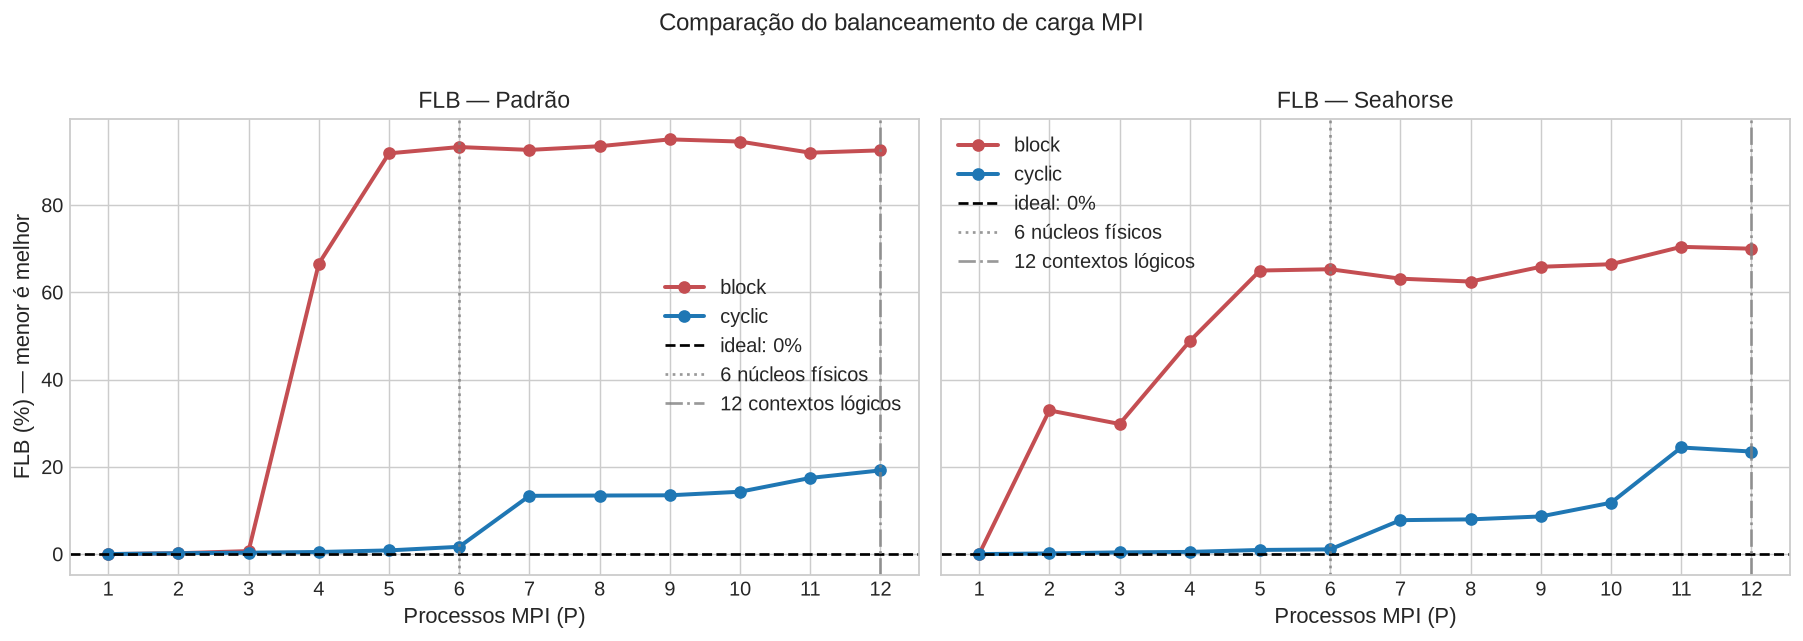

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, agg, titulo in zip(axes, (agg_padrao, agg_seahorse), ('Padrão', 'Seahorse')):
    for estrategia, sub in agg.groupby('estrategia'):
        sub = sub.sort_values('processos')
        ax.plot(sub['processos'], sub['flb_mean'] * 100, marker='o', lw=2.2,
                color=CORES[estrategia], label=estrategia)
    ax.axhline(0, color='black', ls='--', label='ideal: 0%')
    marcar_hardware(ax); ax.set(title=f'FLB — {titulo}', xlabel='Processos MPI (P)')
    ax.set_xticks(range(1, 13)); ax.legend()
axes[0].set_ylabel('FLB (%) — menor é melhor')
fig.suptitle('Comparação do balanceamento de carga MPI', y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / 'fig_mpi_4_flb_padrao_seahorse.png')
plt.show()

## Comparação com OpenMP

A comparação é feita somente como contraste entre memória compartilhada e distribuída no mesmo computador. Para MPI, a referência $T_1$ é a execução do mesmo programa MPI com um processo; isso evita comparar a versão MPI com a otimização de simetria usada pela versão sequencial/OpenMP no caso padrão.

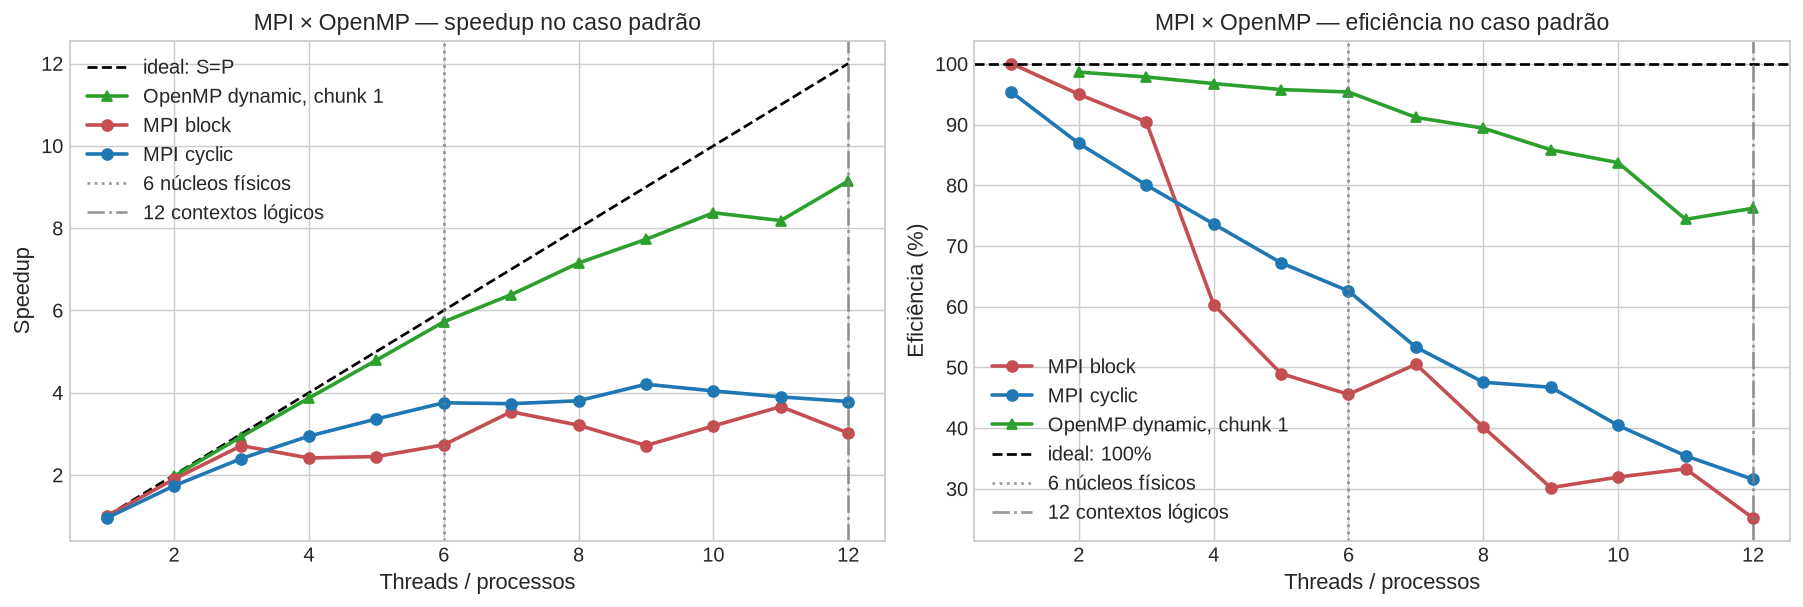

In [10]:
omp_padrao = pd.read_csv(RESULTS / 'benchmark_padrao.csv')
omp_ref = (omp_padrao[(omp_padrao['escalonamento'] == 'dynamic') & (omp_padrao['chunk'] == 1)]
           .groupby('threads', as_index=False).agg(speedup=('speedup', 'mean'),
                                             eficiencia=('eficiencia', 'mean')))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
p = np.arange(1, 13)
ax1.plot(p, p, 'k--', label='ideal: S=P')
ax1.plot(omp_ref['threads'], omp_ref['speedup'], marker='^', lw=2, color=CORES['openmp'],
         label='OpenMP dynamic, chunk 1')
for estrategia, sub in agg_padrao.groupby('estrategia'):
    ax1.plot(sub['processos'], sub['speedup_mean'], marker='o', lw=2,
             color=CORES[estrategia], label=f'MPI {estrategia}')
    ax2.plot(sub['processos'], sub['eficiencia_mean'] * 100, marker='o', lw=2,
             color=CORES[estrategia], label=f'MPI {estrategia}')
ax2.plot(omp_ref['threads'], omp_ref['eficiencia'] * 100, marker='^', lw=2, color=CORES['openmp'],
         label='OpenMP dynamic, chunk 1')
ax2.axhline(100, color='black', ls='--', label='ideal: 100%')
for ax, ylab in ((ax1, 'Speedup'), (ax2, 'Eficiência (%)')):
    marcar_hardware(ax); ax.set(xlabel='Threads / processos', ylabel=ylab); ax.legend()
ax1.set_title('MPI × OpenMP — speedup no caso padrão')
ax2.set_title('MPI × OpenMP — eficiência no caso padrão')
fig.tight_layout()
fig.savefig(PLOTS / 'fig_mpi_5_comparacao_openmp.png')
plt.show()

## Síntese automática e reprodutibilidade

A distribuição cíclica tende a apresentar FLB menor em regiões do fractal cuja carga está concentrada em algumas faixas horizontais. Ela acrescenta comunicação e rearranjo no processo raiz; a melhor estratégia deve, portanto, ser escolhida pelo $T_p$ medido, e não apenas pelo FLB.

Para renovar os dados: `RUNS=5 PROCESSES="1 2 3 4 5 6 7 8 9 10 11 12" ./scripts/benchmark_mpi.sh` e `MODE_ARGS="--seahorse" RUNS=5 ./scripts/benchmark_mpi.sh`. Em seguida, execute todas as células deste notebook.

In [11]:
for nome, agg in [('Padrão', agg_padrao), ('Seahorse', agg_seahorse)]:
    melhor = agg.loc[agg['tp_mean'].idxmin()]
    print(f'{nome}: melhor configuração = {melhor.estrategia}, P={int(melhor.processos)}, '
          f'Tp={melhor.tp_mean:.6f} s, S={melhor.speedup_mean:.3f}, '
          f'E={melhor.eficiencia_mean:.2%}, FLB={melhor.flb_mean:.2%}.')

Padrão: melhor configuração = cyclic, P=9, Tp=0.199039 s, S=4.206, E=46.74%, FLB=13.47%.
Seahorse: melhor configuração = cyclic, P=10, Tp=0.500518 s, S=6.365, E=63.65%, FLB=11.77%.
